<a href="https://colab.research.google.com/github/fluids/AI4GSD/blob/main/Demo_Colab/Demo2_Smartphone_Photos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI4GSD Demo
------------------------------------------
## Smartphone photos
------------------------------------------
#### Table of contents
#### 0. Installing requried packages
#### 1. Importing required packages
#### 2. Defining working directory
#### 3. Extracting or copying your videos/photos to desired folder
#### 4. Obtaining scales from AI, drone flight data, or manual measurements
#### 5. Obtaining segmentation of anthropogenic objects
#### 6. Obtaining grain size data
#### 7. Applying quality control
#### 8. Data visualization

##### *** Please contact Yunxiang Chen, yunxiang.chen@pnnl.gov for reporting errors

------------------------------------------
### 0. Installing requried packages

#### 0a. Install requried packages

In [ ]:
%pip install -q ultralytics==8.3.186 natsort pyproj PyExifTool piexif imutils shapely psutil gdown

#### 0b. Connect Google drive to Colab runtime.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#### 0c. Create AI4GSD parent direcotry and download source codes if not found.

In [ ]:
import sys, subprocess
from pathlib import Path
WorkDir = Path("/content/drive/MyDrive/AI4GSD")
sys.path.insert(0,str(WorkDir))
if not WorkDir.exists():subprocess.run(["git", "clone", "--progress","https://github.com/pnnl/AI4GSD.git", str(WorkDir)],check=True)

### 1. Importing required packages

In [ ]:
import AI4GSD

### 2. Defining working directory

In [ ]:
AI4GSD.pcinfo()
foldername = '20250517_YC_SmartphoneParkTest'                               # Parent folder where you save photos/videos.
PhotoDir = str(WorkDir / 'Demo_Data' / foldername)                          # AI4GSD use string path.

Machine name: 9999a2ab912c
Operating system: Ubuntu 24.04.5 LTS
Architecture: x86_64
Processor: AMD EPYC 7B12
Reported CPU frequency: 2.25 GHz
PyTorch version: 2.14.1+cpu
CUDA available: False
CUDA GPU unavailable to PyTorch


### 3. Extracting or copying your videos/photos to desired folder

In [ ]:
AI4GSD.getPhotos(PhotoDir,nframe=2000, overwrite=False)                    # Use once.

### 4. Obtaining scales from AI, drone flight data, or manual measurements

In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.OverWriteAll = True                                                     # Overwrite everything if True.
PP.OverWriteScaleFile = False
PP.OverWriteScaleRows = True
PP.ScaleSource = 'AI'                                                      # Use AI option.
PP.ModelName = 'YOLO11m.1280.20250825'                                     # Which AI to use.
PP.ComputingSource = 'local'                                               # What computing resource to use.
PP.ImageSizeFactor = 1                                                     # Do you need to user a larger image size for inference?
PP.ConfidenceThresholdUser = 0.85                                          # Minimum confidence threshold.
PP.YOLOSave = False                                                        # Need to save AI prediction to folder.
scales =  AI4GSD.metadata(PP)

Generating scale file for: 20250517_YC_SmartphoneParkTest
Estimating photo resolution via local AI model: YOLO11m.1280.20250825
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Model layer: 113, model parmeter: 20.06M, submodule number: 409
IOU: 0.45, user confidence: 0.85
1/5: photo 1/5, IMG_9581.JPG, scale greencap, res 0.21 mm/px, status 200, (20.00%), 10.74 s
2/5: photo 2/5, IMG_9582.JPG, scale greencap, res 0.49 mm/px, status 200, (40.00%), 5.48 s
3/5: photo 3/5, IMG_9583.JPG, scale greencap, res 0.05 mm/px, status 200, (60.00%), 4.88 s
4/5: photo 4/5, IMG_9584.JPG, scale greencap, res 0.25 mm/px, status 200, (80.00%), 4.66 s
5/5: photo 5/5, IMG_9585.JPG, scale greencap, res 0.46 mm/px, status 200, (100.00%), 4.93 s
Total t

### 5. Obtaining segmentation of anthropogenic objects

In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.FolderLevel = 'L1'
PP.ModelName = 'YOLO11m.640.20250906'
PP.ObjectName = 'anthro'
PP.OverWriteSegementation = False
PP.YOLOSave = False
PP.YOLOIOU = 0.45
PP.ComputingSource = 'local'
PP.ImageSizeType = 'default'
PP.ImageSizeFactor=1
PP.SegmentationClassName = ['board','redbag','people']                     # What object class need to track.
AI4GSD.background(PP)

-----------------------------------------------------------------
Folder name: 20250517_YC_SmartphoneParkTest
output name: segments
Model name: YOLO11m.640.20250906 from local for anthro
Model layer: 125, model parmeter: 22.37M, submodule number: 445
IOU: 0.45, user confidence: 0.35
Number of photos: 5, number of exluded photos 0
20250517_YC_SmartphoneParkTest: 1/5, IMG_9581.JPG, mask existed, skipping... (20.00%)
20250517_YC_SmartphoneParkTest: 2/5, IMG_9582.JPG, mask existed, skipping... (40.00%)
20250517_YC_SmartphoneParkTest: 3/5, IMG_9583.JPG, mask existed, skipping... (60.00%)
20250517_YC_SmartphoneParkTest: 4/5, IMG_9584.JPG, mask existed, skipping... (80.00%)
20250517_YC_SmartphoneParkTest: 5/5, IMG_9585.JPG, mask existed, skipping... (100.00%)
Total time: 7.63 s, time per photo 1.53 s
-----------------------------------------------------------------



### 6. Obtaining grain size data

AI4GSD: an AI and cloud powered tool for grain size quantification
AI models in use: YOLO11m.1280.20250322
Confidence thresholds in use: 0.35

-----------------------------------------------------------------
Folder name: 20250517_YC_SmartphoneParkTest
Output folder: 20250517_YC_SmartphoneParkTest_YOLO11m.1280.20250322_35
Model name: YOLO11m.1280.20250322 from local for rock detection
Model layer: 113, model parmeter: 20.05M, submodule number: 409
IOU: 0.45, YOLO confidence: 0.25, user confidence: 0.35
Number of photos: 5, number of exluded photos 0
1/5: IMG_9581.JPG, resolution 0.21 mm/px (20.00%), 0.00 s
Detected 3753 rocks, diagonal and count based D10, D50, D60, and D84 are: 0.98, 1.53, 1.67, and 2.20 cm
Detected 3753 rocks, diagonal and area  based D10, D50, D60, and D84 are: 1.25, 2.01, 2.20, and 2.89 cm


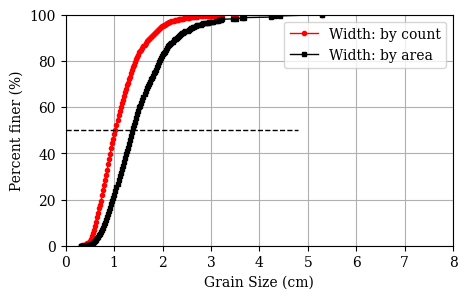

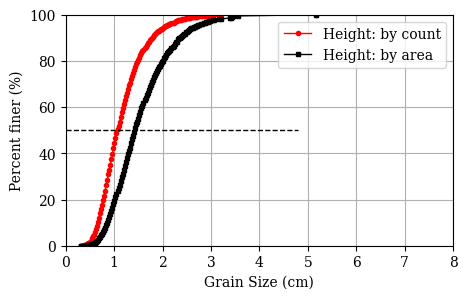

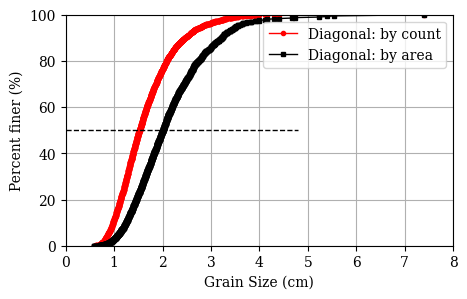

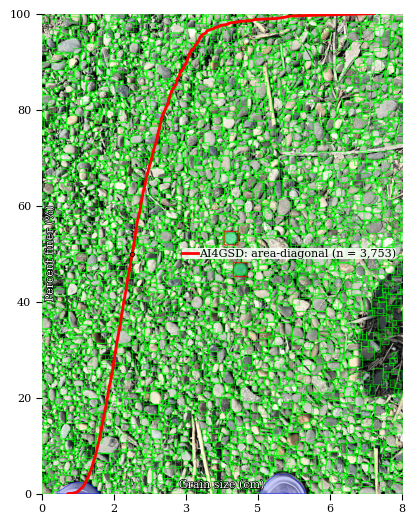

2/5: IMG_9582.JPG, resolution 0.49 mm/px (40.00%), 13.79 s
Detected 5387 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.63, 2.21, 2.37, and 2.90 cm
Detected 5387 rocks, diagonal and area  based D10, D50, D60, and D84 are: 1.82, 2.56, 2.75, and 3.43 cm


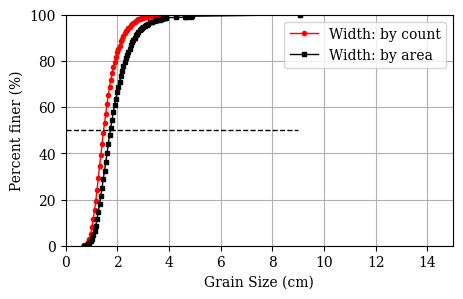

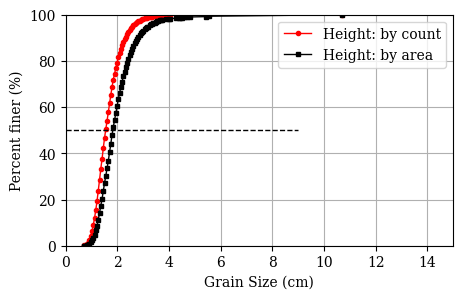

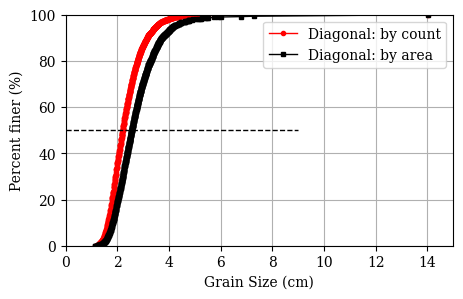

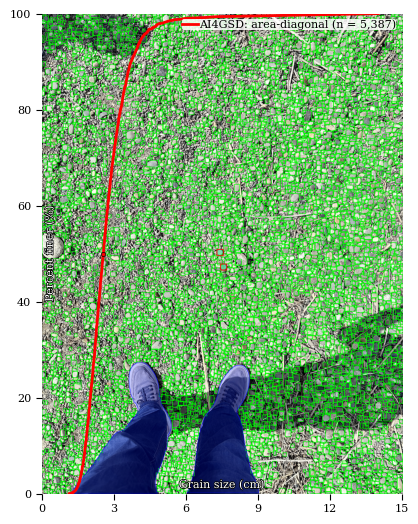

3/5: IMG_9583.JPG, resolution 0.05 mm/px (60.00%), 12.01 s
Detected 450 rocks, diagonal and count based D10, D50, D60, and D84 are: 0.56, 1.13, 1.25, and 1.63 cm
Detected 450 rocks, diagonal and area  based D10, D50, D60, and D84 are: 0.94, 1.57, 1.73, and 2.48 cm


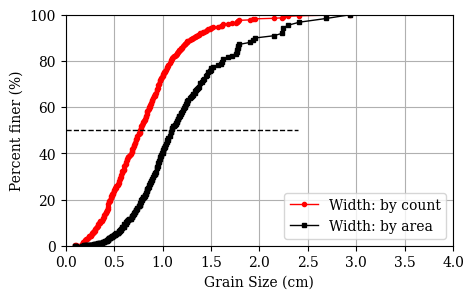

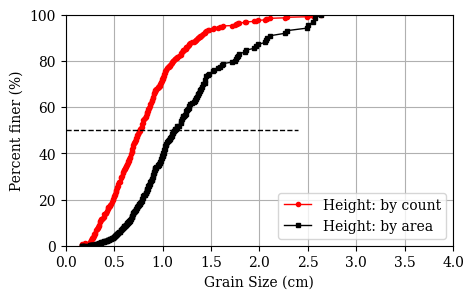

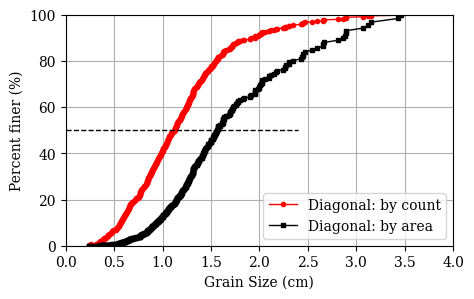

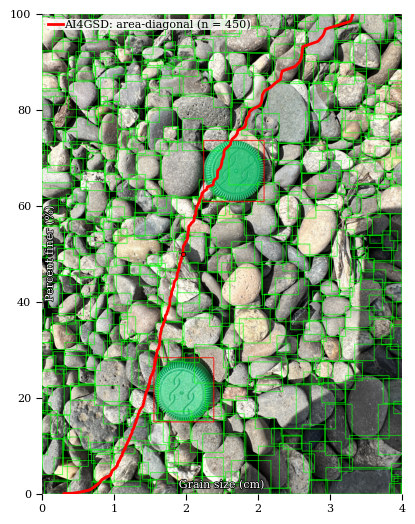

4/5: IMG_9584.JPG, resolution 0.25 mm/px (80.00%), 10.47 s
Detected 4159 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.03, 1.54, 1.67, and 2.18 cm
Detected 4159 rocks, diagonal and area  based D10, D50, D60, and D84 are: 1.27, 1.96, 2.16, and 2.89 cm


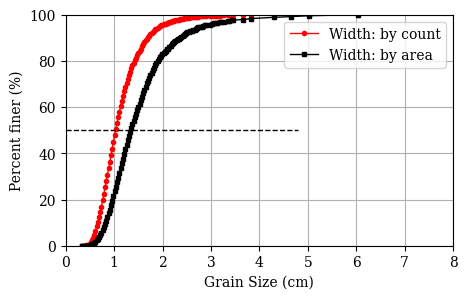

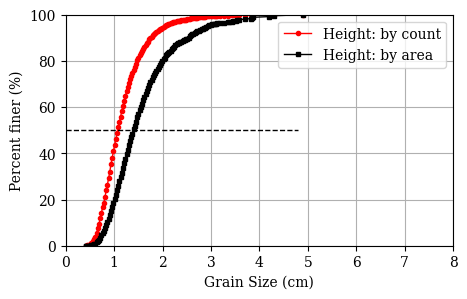

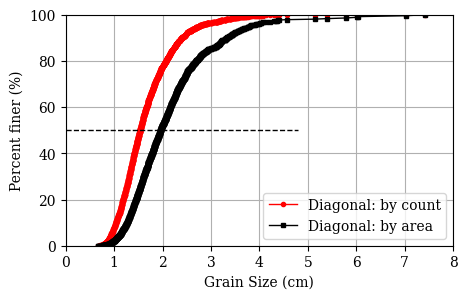

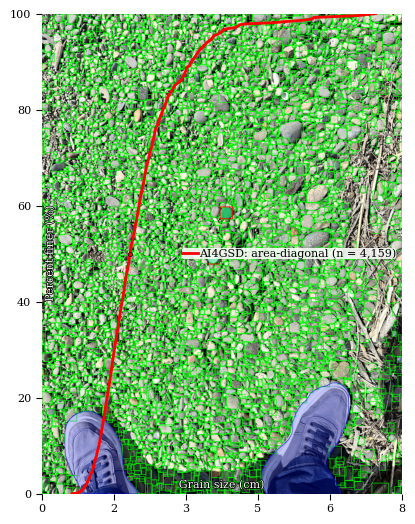

5/5: IMG_9585.JPG, resolution 0.46 mm/px (100.00%), 12.49 s
Detected 5390 rocks, diagonal and count based D10, D50, D60, and D84 are: 1.57, 2.14, 2.29, and 2.83 cm
Detected 5390 rocks, diagonal and area  based D10, D50, D60, and D84 are: 1.77, 2.53, 2.75, and 3.62 cm


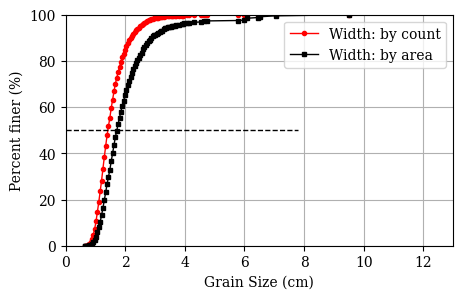

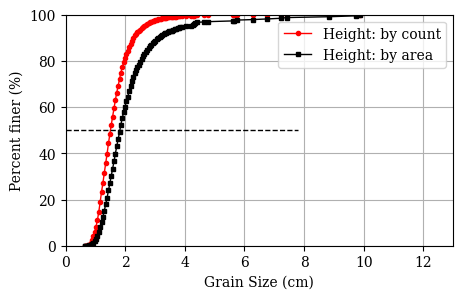

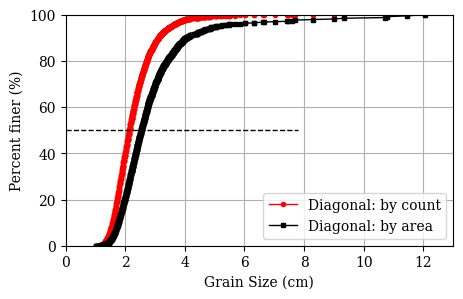

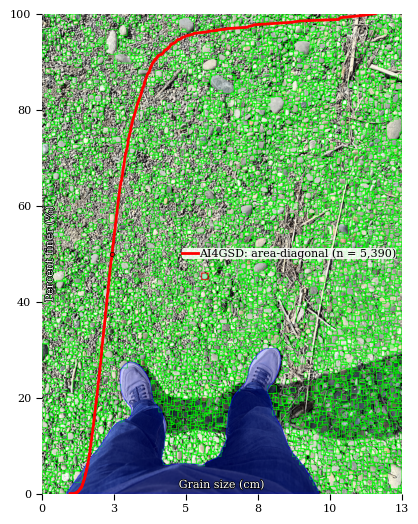

Output folder summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20250517_YC_SmartphoneParkTest/grains_predicts/20250517_YC_SmartphoneParkTest_YOLO11m.1280.20250322_35/Statistics_V3_20250517_YC_SmartphoneParkTest_YOLO11m.1280.20250322_35.csv
Total number of grains: 19139, number of grains per photo: 3827.80
Total time: 65.34 s, time per photo 13.07 s

Output all summary data to: /content/drive/MyDrive/AI4GSD/Demo_Data/20250517_YC_SmartphoneParkTest/Statistics_V3_20250517_YC_SmartphoneParkTest_YOLO11m.1280.20250322_35.csv
Total execution time: 65.68 s


In [ ]:
PP = AI4GSD.parameters()
PP.Directory = PhotoDir
PP.ModelName = 'YOLO11m.1280.20250322'
PP.ImageSizeFactor = 1
PP.LineThickness = 2
PP.YOLOSave = False
PP.SaveOverlayLabel = False
PP.OverWriteAll = True
PP.PrintOnScreen = True
PP.OverlayFontSize = 4
PP.OverlayLegendFontSize = 4
PP.OverlayGSDTickLineWidth = 4
gsd = AI4GSD.Photo2GSD(PP)

### 7. Applying quality control

In [ ]:
gsdqc, stqc = AI4GSD.qualityControl(PhotoDir)


Quality control summary for 20250517_YC_SmartphoneParkTest:
Photos: time 31.0 s, area 6.8 m2, valid area 6.8 m2 (100.0%), frame 5, valid frame 5 (100.0%)
Photos: grain number 19139, number per image 3827.8; efficiency 0.2 m2/s, 617.4 grains/s


### 8. Data visualization

#### Metadata and pixel sizes for all images

In [ ]:
print(scales.head(10).T.to_string())

                                                                             0                                1
Name                                                         DJI_0113_2000.png                DJI_0113_4000.png
Folder                                         20241130_YC_DroneVideoFieldTest  20241130_YC_DroneVideoFieldTest
Scale_source                                                               log                              log
L1_px1_pixel                                                           -9999.0                          -9999.0
L1_py1_pixel                                                           -9999.0                          -9999.0
L1_px2_pixel                                                           -9999.0                          -9999.0
L1_py2_pixel                                                           -9999.0                          -9999.0
L2_px1_pixel                                                           -9999.0                          

#### Grain size data before quality control

In [ ]:
print(gsd.head(10).T.to_string())

                                                                                                      0                                                         1
Name                                                                                  DJI_0113_2000.png                                         DJI_0113_4000.png
Folder                                                                  20241130_YC_DroneVideoFieldTest                           20241130_YC_DroneVideoFieldTest
Save_folder                                    20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35  20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35
Model_ID                                                                          YOLO11m.1280.20250322                                     YOLO11m.1280.20250322
Scale_source                                                                                        log                                                       log
L1_px1_pixel                

#### Grain size data after quality control

In [ ]:
print(gsdqc.head(10).T.to_string())

                                                                                                      0
Name                                                                                  DJI_0113_4000.png
Folder                                                                  20241130_YC_DroneVideoFieldTest
Save_folder                                    20241130_YC_DroneVideoFieldTest_YOLO11m.1280.20250322_35
Model_ID                                                                          YOLO11m.1280.20250322
Scale_source                                                                                        log
L1_px1_pixel                                                                                    -9999.0
L1_py1_pixel                                                                                    -9999.0
L1_px2_pixel                                                                                    -9999.0
L1_py2_pixel                                                    

#### Summary for each video

In [ ]:
print(stqc.head(10).T.to_string())

                                                            0
Folder                        20241130_YC_DroneVideoFieldTest
Data_type                                                 0.0
Video_ID                                                  0.0
Video_name                                              113.0
Frame_rate_fps                                      23.976024
Width_px                                               5472.0
Height_px                                              3078.0
Dimension_megapixel                                 16.842816
Duration_s                                         240.198292
Grain_number_qc0                                       3122.0
Area_qc0_m2                                         14.765748
Area_qc2_m2                                          8.975421
Area_ratio_qc2                                       0.607854
Total_frame                                               2.0
Frame_qc0                                                 2.0
Frame_qc